# Homework 4 Autoencoders Solution by Ahad

#### Imports

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

set_seed()
device = get_device()
print("Using device:", device)
print("PyTorch version:", torch.__version__)

Using device: mps
PyTorch version: 2.14.0


#### Load MNIST For Assignments

In [2]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reusing my MNIST data files from Homework 3
DATA_ROOT = "../Homework/Homework 3/data"

def load_mnist(batch_size=128, seed=SEED):
    transform = transforms.ToTensor()

    train_dataset = datasets.MNIST(
        root=DATA_ROOT,
        train=True,
        download=False,
        transform=transform
    )

    test_dataset = datasets.MNIST(
        root=DATA_ROOT,
        train=False,
        download=False,
        transform=transform
    )

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True, 
        generator=generator
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False 
    )

    return train_loader, test_loader

In [3]:
train_loader, test_loader = load_mnist()

#### Inspect Data

In [4]:
print("Training samples:", len(train_loader.dataset))
print("Test samples:", len(test_loader.dataset))

images, labels = next(iter(train_loader))

# Copied from HW 3 since using same data
print("Images shape:", images.shape) # (batch, channels, height, width)
print("Labels shape:", labels.shape)
print("Min pixel value:", images.min().item())
print("Max pixel value:", images.max().item())

Training samples: 60000
Test samples: 10000
Images shape: torch.Size([128, 1, 28, 28])
Labels shape: torch.Size([128])
Min pixel value: 0.0
Max pixel value: 1.0


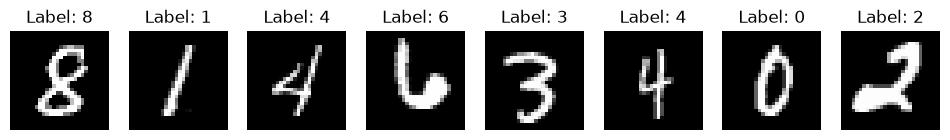

In [5]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.show()

#### Convolutional Autoencoder

In [6]:
# Reusable class for all 3 homework sections
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()

        # Encode: 1x28x28 -> 16x14x14 -> 32x7x7 -> latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, latent_dim)
        )

        # Decoder: latent_dim -> 32x7x7 -> 16x14x14 -> 1x28x28
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 7 * 7),
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

def initialize_model(latent_dim=20):
    set_seed()
    return ConvAutoencoder(latent_dim).to(device)

In [7]:
model = initialize_model()
print(model)

# Shape check: one batch through the encoder and the full model
sample = images[:8].to(device)

with torch.no_grad():
    latent = model.encoder(sample)
    reconstruction = model(sample)

print("Input shape:", sample.shape)
print("Latent shape:", latent.shape)
print("Reconstruction shape:", reconstruction.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=1568, out_features=20, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=20, out_features=1568, bias=True)
    (1): Unflatten(dim=1, unflattened_size=(32, 7, 7))
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (5): Sigmoid()
  )
)
Input shape: torch.Size([8, 1, 28, 28])
Latent shape: torch.Size([8, 20])
Reconstruction shape: torch.Size([8, 1, 28, 28])
Parameters: 73877


#### Training and Evaluation Functions

In [8]:
def add_gaussian_noise(images, sigma, generator=None):
    noise = torch.randn(images.shape, generator=generator) * sigma
    noisy = images + noise.to(images.device)
    return noisy.clamp(0.0, 1.0)

In [9]:
loss_function = nn.MSELoss()

def train_autoencoder(model, loader, epochs=20, lr=1e-3, noise_sigma=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    epoch_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, _ in loader: # Note to self: labels are not used by an autoencoder
            images = images.to(device)

            inputs = images if noise_sigma is None else add_gaussian_noise(images, noise_sigma)

            optimizer.zero_grad()

            reconstructions = model(inputs)

            loss = loss_function(reconstructions, images)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)

        epoch_loss = total_loss / len(loader.dataset)
        epoch_losses.append(epoch_loss)
        print(f"Epoch {epoch+1}: Loss = {epoch_loss:.6f}")

    return epoch_losses

In [10]:
def evaluate_mse(model, loader, noise_sigma=None, seed=SEED):
    model.eval()
    total_loss = 0
    
    generator = torch.Generator().manual_seed(seed)

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            inputs = images if noise_sigma is None else add_gaussian_noise(images, noise_sigma, generator)

            reconstructions = model(inputs)

            loss = loss_function(reconstructions, images)

            total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)

### Coding Assignment 1: Convolutional Autoencoder

#### Train the CAE

In [11]:
cae_model = initialize_model(latent_dim=20)

start = time.time()
cae_losses = train_autoencoder(cae_model, train_loader, epochs=20, lr=1e-3)
cae_train_time = time.time() - start

print(f"Training time: {cae_train_time:.1f} seconds")

Epoch 1: Loss = 0.051226
Epoch 2: Loss = 0.017071
Epoch 3: Loss = 0.014534
Epoch 4: Loss = 0.013058
Epoch 5: Loss = 0.011967
Epoch 6: Loss = 0.011139
Epoch 7: Loss = 0.010509
Epoch 8: Loss = 0.010026
Epoch 9: Loss = 0.009660
Epoch 10: Loss = 0.009373
Epoch 11: Loss = 0.009149
Epoch 12: Loss = 0.008958
Epoch 13: Loss = 0.008789
Epoch 14: Loss = 0.008659
Epoch 15: Loss = 0.008538
Epoch 16: Loss = 0.008430
Epoch 17: Loss = 0.008344
Epoch 18: Loss = 0.008253
Epoch 19: Loss = 0.008179
Epoch 20: Loss = 0.008111
Training time: 142.7 seconds


#### Test MSE

In [12]:
cae_test_mse = evaluate_mse(cae_model, test_loader)
print(f"CAE Test MSE: {cae_test_mse:.6f}")

CAE Test MSE: 0.007992


#### Original vs. Reconstructed Digits

In [13]:
def plot_reconstructions(image_rows, row_titles, n=8):
    # image_rows: list of image batches (one per row), each shaped (N, 1, 28, 28)
    fig, axes = plt.subplots(len(image_rows), n, figsize=(1.5 * n, 1.8 * len(image_rows)), squeeze=False)

    for row, (batch, title) in enumerate(zip(image_rows, row_titles)):
        for col in range(n):
            ax = axes[row, col]
            ax.imshow(batch[col].detach().cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_ylabel(title, rotation=0, ha="right", va="center", fontsize=10)

    plt.tight_layout()
    plt.show()

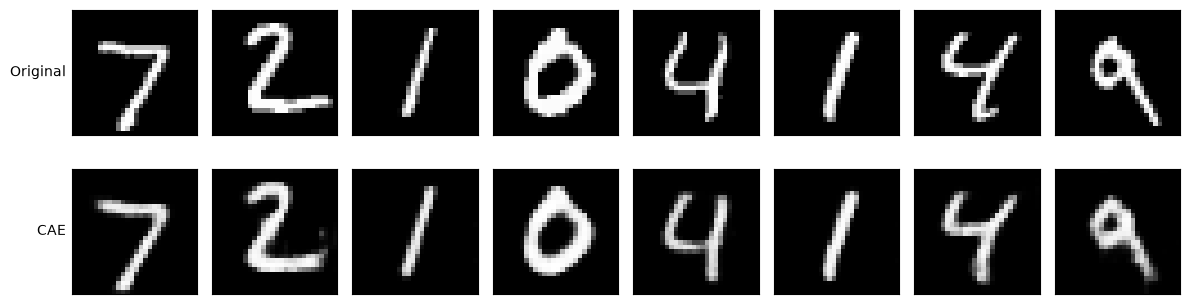

In [14]:
test_images, _ = next(iter(test_loader))
test_images = test_images[:8].to(device)

cae_model.eval()
with torch.no_grad():
    cae_reconstructions = cae_model(test_images)

plot_reconstructions(
    [test_images, cae_reconstructions],
    ["Original", "CAE"]
)

### Coding Assignment 2: Denoising Convolutional Autoencoder

#### Train the DCAE (Noisy Input, Clean Target)

In [15]:
TRAIN_NOISE_SIGMA = 0.3

dcae_model = initialize_model(latent_dim=20) # same architecture and same starting weights as the CAE

start = time.time()
dcae_losses = train_autoencoder(dcae_model, train_loader, epochs=20, lr=1e-3, noise_sigma=TRAIN_NOISE_SIGMA)
dcae_train_time = time.time() - start

print(f"Training time: {dcae_train_time:.1f} seconds")

Epoch 1: Loss = 0.052365
Epoch 2: Loss = 0.020702
Epoch 3: Loss = 0.017759
Epoch 4: Loss = 0.015988
Epoch 5: Loss = 0.014556
Epoch 6: Loss = 0.013467
Epoch 7: Loss = 0.012714
Epoch 8: Loss = 0.012173
Epoch 9: Loss = 0.011792
Epoch 10: Loss = 0.011506
Epoch 11: Loss = 0.011262
Epoch 12: Loss = 0.011084
Epoch 13: Loss = 0.010932
Epoch 14: Loss = 0.010792
Epoch 15: Loss = 0.010667
Epoch 16: Loss = 0.010573
Epoch 17: Loss = 0.010493
Epoch 18: Loss = 0.010402
Epoch 19: Loss = 0.010328
Epoch 20: Loss = 0.010263
Training time: 155.5 seconds


#### Test MSE at Multiple Noise Levels: CAE vs. DCAE

In [16]:
import pandas as pd

TEST_NOISE_LEVELS = [0.1, 0.3, 0.5]

def compare_models_across_noise(models, loader, noise_levels=TEST_NOISE_LEVELS):
    results = {}
    for name, model in models.items():
        results[name] = [evaluate_mse(model, loader, noise_sigma=sigma) for sigma in noise_levels]

    return pd.DataFrame(results, index=pd.Index(noise_levels, name="Test noise (sigma)"))

In [17]:
noise_results = compare_models_across_noise(
    {"CAE (trained clean)": cae_model, "DCAE (trained sigma=0.3)": dcae_model},
    test_loader
)
noise_results

,CAE (trained clean),DCAE (trained sigma=0.3)
Test noise (sigma),,
0.1,0.019162,0.008751
0.3,0.068395,0.010116
0.5,0.128864,0.018549


#### Clean | Noisy | DCAE Reconstruction

Test noise sigma = 0.1


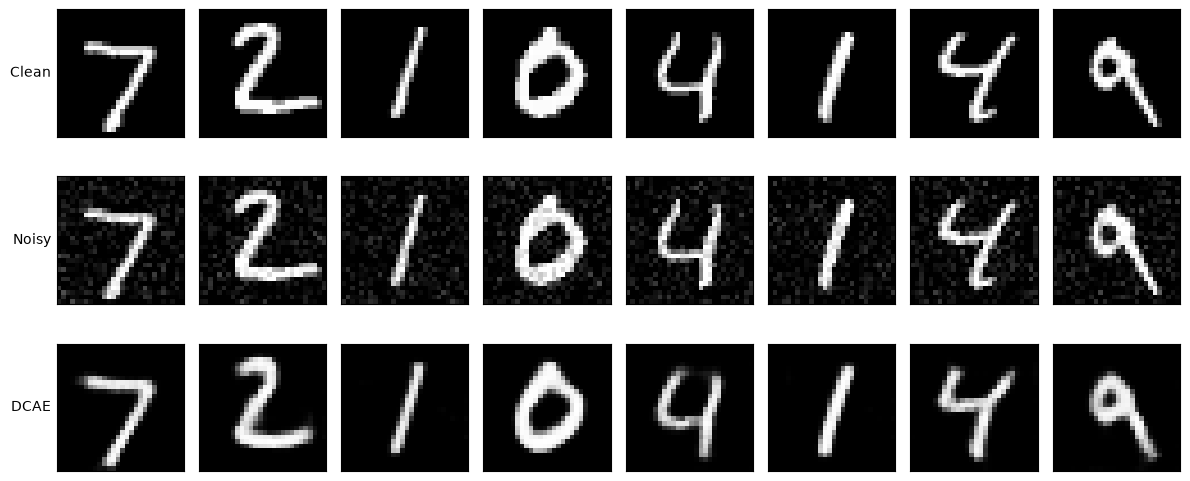

Test noise sigma = 0.3


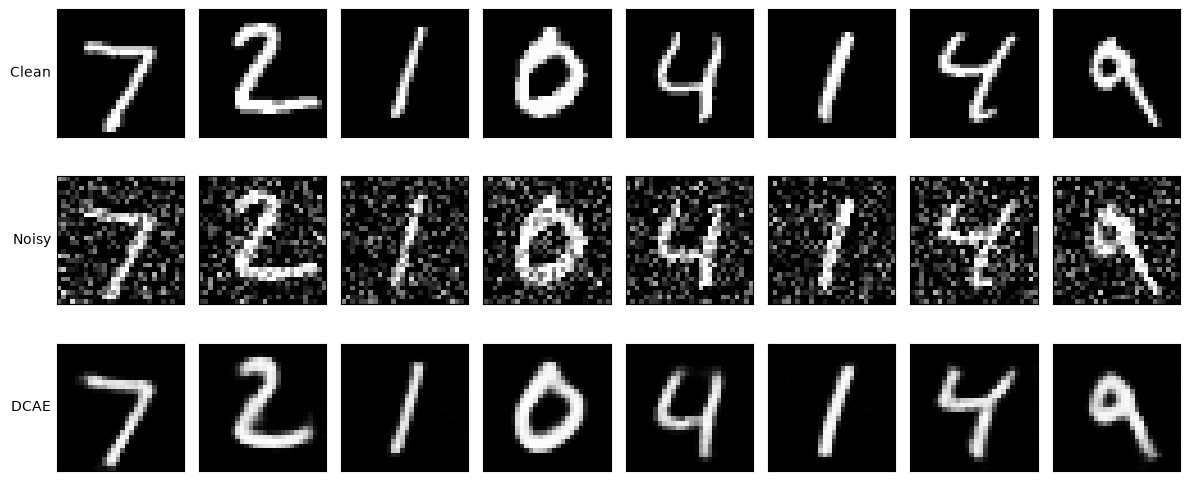

Test noise sigma = 0.5


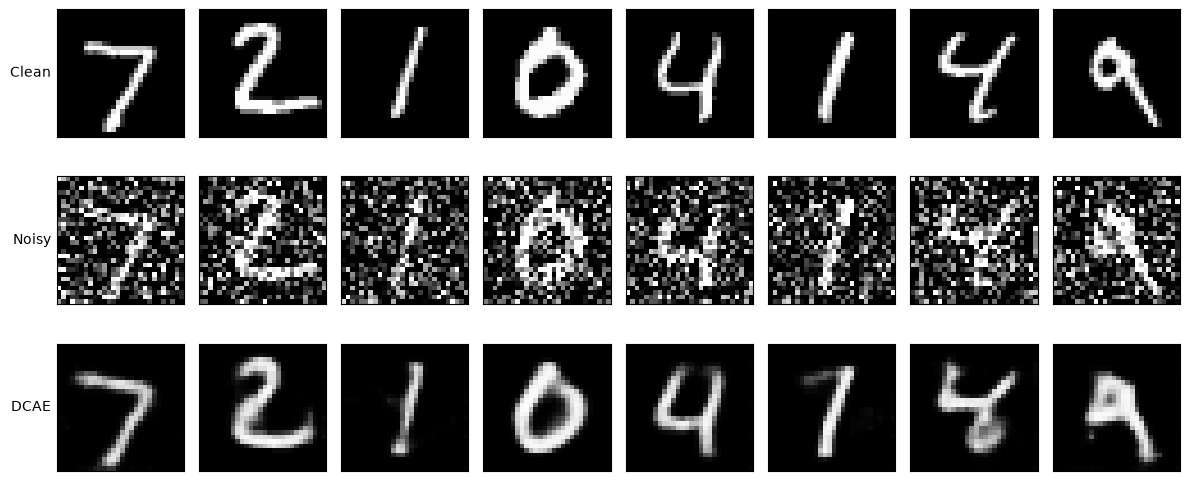

In [18]:
def show_denoising(sigma, n=8, seed=SEED):
    test_images, _ = next(iter(test_loader))
    clean = test_images[:n].to(device)

    generator = torch.Generator().manual_seed(seed)
    noisy = add_gaussian_noise(clean, sigma, generator)

    dcae_model.eval()
    with torch.no_grad():
        denoised = dcae_model(noisy)

    print(f"Test noise sigma = {sigma}")
    plot_reconstructions([clean, noisy, denoised], ["Clean", "Noisy", "DCAE"], n=n)

for sigma in TEST_NOISE_LEVELS:
    show_denoising(sigma)

### Coding Assignment 3: Convolutional Autoencoder vs. PCA

#### Train the CAE with Latent Dimension k = 10

In [19]:
K = 10 # latent dimensions

cae10_model = initialize_model(latent_dim=K)

start = time.time()
cae10_losses = train_autoencoder(cae10_model, train_loader, epochs=20, lr=1e-3)
cae10_train_time = time.time() - start

print(f"Training time: {cae10_train_time:.1f} seconds")

Epoch 1: Loss = 0.057368
Epoch 2: Loss = 0.028810
Epoch 3: Loss = 0.024637
Epoch 4: Loss = 0.022154
Epoch 5: Loss = 0.020721
Epoch 6: Loss = 0.019802
Epoch 7: Loss = 0.019138
Epoch 8: Loss = 0.018629
Epoch 9: Loss = 0.018208
Epoch 10: Loss = 0.017884
Epoch 11: Loss = 0.017607
Epoch 12: Loss = 0.017380
Epoch 13: Loss = 0.017165
Epoch 14: Loss = 0.016975
Epoch 15: Loss = 0.016812
Epoch 16: Loss = 0.016653
Epoch 17: Loss = 0.016518
Epoch 18: Loss = 0.016402
Epoch 19: Loss = 0.016301
Epoch 20: Loss = 0.016194
Training time: 130.3 seconds


#### PCA + Reconstruction Helper Functions

In [20]:
from sklearn.decomposition import PCA

def get_flattened_images(loader):
    # Same pixels the loader serves ([0, 1] floats), flattened to (N, 784) for PCA
    return (loader.dataset.data.float() / 255.0).reshape(len(loader.dataset), -1).numpy()

def synchronize():
    # GPU work is asynchronous
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

def fit_pca(train_flat, k):
    start = time.time()
    pca = PCA(n_components=k, random_state=SEED).fit(train_flat)
    return pca, time.time() - start

def pca_reconstruct(pca, flat_images):
    start = time.time()
    reconstructions = pca.inverse_transform(pca.transform(flat_images)) # project down to k, then back up to 784
    return reconstructions, time.time() - start

def cae_reconstruct(model, flat_images):
    images = torch.from_numpy(flat_images).reshape(-1, 1, 28, 28).to(device)
    model.eval()

    synchronize()
    start = time.time()
    with torch.no_grad():
        reconstructions = model(images)
    synchronize()
    elapsed = time.time() - start

    return reconstructions.cpu().reshape(len(flat_images), -1).numpy(), elapsed

def flat_mse(images, reconstructions):
    return float(np.mean((images - reconstructions) ** 2))

#### Fit PCA and Compare Test MSE

In [24]:
train_flat = get_flattened_images(train_loader)
test_flat = get_flattened_images(test_loader)

pca, pca_fit_time = fit_pca(train_flat, K)
pca_recon, pca_infer_time = pca_reconstruct(pca, test_flat)
cae10_recon, cae10_infer_time = cae_reconstruct(cae10_model, test_flat)

pca_test_mse = flat_mse(test_flat, pca_recon)
cae10_test_mse = flat_mse(test_flat, cae10_recon)

print(f"PCA (k={K}) test MSE: {pca_test_mse:.6f}")
print(f"CAE (k={K}) test MSE: {cae10_test_mse:.6f}")
print(f"CAE MSE from evaluate_mse: {evaluate_mse(cae10_model, test_loader):.6f}")

PCA (k=10) test MSE: 0.034074
CAE (k=10) test MSE: 0.015922
CAE MSE from evaluate_mse: 0.015922


#### Reconstruction of 5 Sample Digits: Original vs. CAE vs. PCA

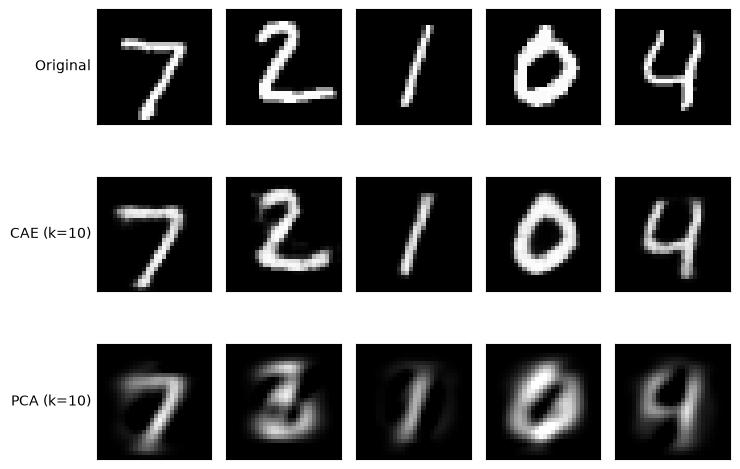

In [22]:
def to_images(flat_images):
    return torch.from_numpy(flat_images).reshape(-1, 1, 28, 28)

n_samples = 5

plot_reconstructions(
    [to_images(test_flat[:n_samples]), to_images(cae10_recon[:n_samples]), to_images(pca_recon[:n_samples])],
    ["Original", f"CAE (k={K})", f"PCA (k={K})"],
    n=n_samples
)

#### MSE and Speed Comparison

In [23]:
comparison = pd.DataFrame(
    {
        "Test MSE": [cae10_test_mse, pca_test_mse],
        "Training time (s)": [cae10_train_time, pca_fit_time],
        "Inference time, 10k test images (s)": [cae10_infer_time, pca_infer_time],
    },
    index=[f"CAE (k={K})", f"PCA (k={K})"]
)
comparison.style.format({
    "Test MSE": "{:.6f}",
    "Training time (s)": "{:.3f}",
    "Inference time, 10k test images (s)": "{:.4f}",
})

,Test MSE,Training time (s),"Inference time, 10k test images (s)"
CAE (k=10),0.015922,130.330,0.3975
PCA (k=10),0.034074,0.212,0.0155


#### Analysis

When it comes to speed, we can see that PCA trains incredibly fast in comparison the CAE. THe error for PCA is roughly 2.1 times larger than CAE which tells us that CAE performed much better on the 10,000 test images. For inference times, PCA is 26 times faster.

In the grid above, it is very clear that CAE perserves spacial structure better. For PCA, we can see that a lot of the images look blurry and its hard to make out the numbers. Some of the shapes are also incorrect. For example, the reconstructed image with a label: 4 looks like a 9 for the PCA while for CAE on the same test image it is much clearer that it is a 4. Same thing with the number 2, PCA has the bottom line of the 3 curving in a weird manner. It did not learn the features as well. This is because PCA is linear and it compresses images in straight line directions while CAE has nonlinearity (through ReLU) in the convolution layers which can better learn the bends and curve the mapping aroudn the digits shapes. That's why it more accurately decoded the label 2 and 4 as compared to PCA.